<a href="https://colab.research.google.com/github/arjunmagarcode/Healthcare-1A-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/blob/arjunmagar/notebooks/03_evaluation_framework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:


import pandas as pd
import numpy as np

url = " https://raw.githubusercontent.com/Break-Through-Tech/Healthcare-1A-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/main/data/kidney_waitlist_analytic.csv.gz"
print("Dataset is beging loaded, Please wait....")
df = pd.read_csv(url, compression='gzip', low_memory=False)

print(f"Data successfully loaded! Shape: {df.shape}")
df.head()

Dataset is beging loaded, Please wait....
Data successfully loaded! Shape: (494862, 38)


,ON_DIALYSIS,A2A2B_ELIGIBILITY,GENDER,ABO,BMI_TCR,FUNC_STAT_TCR,INIT_STAT,INIT_CPRA,END_CPRA,REM_CD,...,PSTATUS,PTIME,TRR_ID_CODE,DONOR_ID,LISTING_CTR_CODE,outcome,event_adverse,event_transplant,censored,days_to_event
0,Y,NaN,F,B,31.63,2080.0,4099,0.0,0.0,8.0,...,NaN,NaN,NaN,NaN,13609,died,1,0,0,287.0
1,Y,NaN,M,A,30.04,2070.0,4099,0.0,NaN,24.0,...,NaN,NaN,NaN,NaN,6975,removed_administrative,0,0,0,2322.0
2,N,NaN,F,O,32.85,2070.0,4099,0.0,0.0,8.0,...,NaN,NaN,NaN,NaN,19716,died,1,0,0,604.0
3,Y,NaN,M,A,20.00,2090.0,4099,0.0,0.0,13.0,...,NaN,NaN,NaN,NaN,8587,removed_too_sick,1,0,0,909.0
4,Y,NaN,M,AB,23.30,2070.0,4010,0.0,0.0,13.0,...,NaN,NaN,NaN,NaN,18352,removed_too_sick,1,0,0,231.0


In [ ]:
df['event_transplant'].value_counts()

,count
event_transplant,
0,260433
1,234429


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
[col for col in df.columns if 'rem' in col.lower() or 'death' in col.lower() or 'status' in col.lower() or 'event' in col.lower()]

['REM_CD',
 'COMPOSITE_DEATH_DATE',
 'PSTATUS',
 'event_adverse',
 'event_transplant',
 'days_to_event']

In [ ]:
df['event_adverse'].value_counts()

,count
event_adverse,
0,425119
1,69743


In [24]:
# ==========================================
# 1. Imports
# ==========================================

import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score

)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# ==========================================
# 2. Numerical Metrics Function
# ==========================================

def evaluate_risk_model(y_true, y_prob, threshold=0.5):
  """
  Evaluates risk predictions for organ waitlist adverse outcomes.
  """
  # 1. Convert continuous probabilities to binary predictions

  y_pred = (y_prob >= threshold).astype(int)

  # 2. Compute metrics
  metrics = {
      # 1. Ranking & Discrimination (Evaluates y_prob across all thresholds)
      'roc_auc': roc_auc_score(y_true, y_prob),
      'average_precision': average_precision_score(y_true, y_prob),

      # 2. Probability Calibration (Evaluates how realistic the percentages are)
      'brier_score': brier_score_loss(y_true, y_prob),

      # 3. Decision-Level Performance (Evaluates y_pred at ONE specific cutoff)
      'precision': precision_score(y_true, y_pred, zero_division=0),
      'recall': recall_score(y_true, y_pred, zero_division=0),
      #4 F1_score
      'f1_score': f1_score(y_true, y_pred, zero_division=0),

      # 5. Metadata / Settings
      'threshold': threshold
  }

  return metrics

# ==========================================
# 3. Calibration Visualizer Function
# ==========================================

def plot_calibration_curve(y_true, y_prob, n_bins=10, model_name="Risk Model"):
    """
    Plots a reliability curve to visually inspect model calibration.
    """

    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=n_bins)
    plt.figure(figsize=(7, 7))
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
    plt.plot(prob_pred, prob_true, marker='o', linewidth=2, label=model_name)
    plt.xlabel('Mean Predicted Probability')
    plt.ylabel('Observed Fraction of Positives')
    plt.title(f'Calibration Curve ({model_name})')
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.show()

def compute_lift_at_k(y_true, y_prob, top_k=0.10):
    """
    Computes model lift for the top k fraction of predicted highest-risk patients.
    """
    # 1. Determine overall baseline event rate
    overall_rate = np.mean(y_true)
    if overall_rate == 0:
        return 0.0

    # 2. Number of patients in top k
    n_top = int(np.ceil(len(y_prob) * top_k))

    # 3. Get indices of top k highest predicted probabilities
    top_indices = np.argsort(y_prob)[::-1][:n_top]

    # 4. Calculate event rate in the top k group
    top_k_rate = np.mean(np.array(y_true)[top_indices])

    # 5. Lift = (rate in top group) / (overall rate)
    return top_k_rate / overall_rate

Standard Metrics: {'roc_auc': np.float64(0.4987351163826384), 'average_precision': np.float64(0.14063113024591264), 'brier_score': np.float64(0.3337409510894198), 'precision': 0.14017356782338203, 'recall': 0.4981575211849218, 'f1_score': 0.21878463476070528, 'threshold': 0.5}
Lift @ top 10%: 1.00


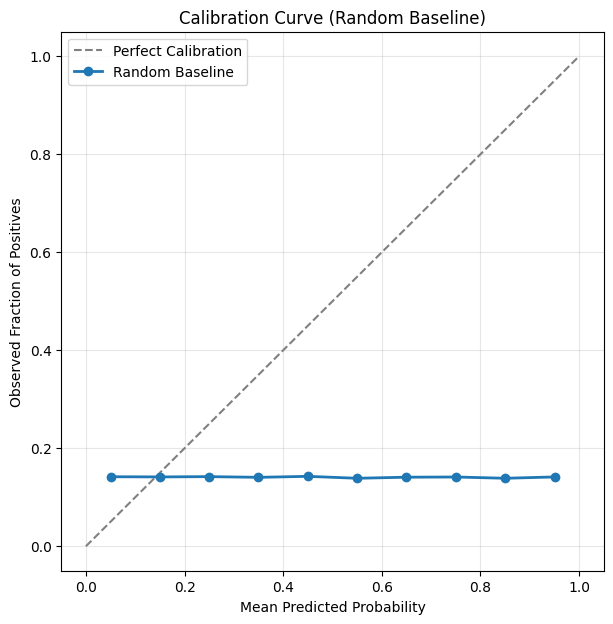

In [28]:
## TEST

# 1. Grab your true ground truth column
y_true = df['event_adverse']

# 2. Generate random guesses between 0.0 and 1.0 for testing
np.random.seed(42)
y_dummy_prob = np.random.uniform(0, 1, size=len(y_true))

# 3. Run your evaluation functions
results = evaluate_risk_model(y_true, y_dummy_prob)
print("Standard Metrics:", results)

# 4. Test lift on the top 10% highest-risk guesses
lift_10 = compute_lift_at_k(y_true, y_dummy_prob, top_k=0.10)
print(f"Lift @ top 10%: {lift_10:.2f}")

# 5. Plot calibration curve
plot_calibration_curve(y_true, y_dummy_prob, model_name="Random Baseline")